# Statistical Exploratory Data Analysis & Quality Audit
## Metro Nashville Accounts Payable Late Payment Prediction

**Author:** Antigravity Data Science Team  
**Dataset:** Metro Nashville Vendor Payments (1,307,617 Raw Line Items -> 811,914 Clean Invoices)  
**Target Variable:** `is_late` ($1$ if `days_to_pay > 30`, else $0$)  
**Artifacts Generated:** `artifacts/eda/*.png`

---

### Objectives
1. **Data Audit Funnel**: Audit data cleaning transitions from raw line items to unified invoice grain.
2. **Distribution & Skewness Profiling**: Quantify heavy tails, extreme outliers, and assess median/IQR vs. mean/std.
3. **Right-Censoring Verification**: Empirically validate the 61-day buffer (`test_end = 2025-10-31`) before dataset truncation (`max(Payment_Date) = 2025-12-31`).
4. **Threshold Sensitivity & Fiscal Seasonality**: Compare Net 30 vs Net 45 definitions and quantify June fiscal year-end acceleration.
5. **Statistical Hypothesis Testing**: Rigorously test multi-department delays, high-value prioritization, and operating unit disparities using Mann-Whitney U and Chi-Square tests.
6. **Vendor Concentration & Pareto Analysis**: Uncover spend and operational risk concentration across suppliers.

In [1]:
import sys
from pathlib import Path
import json
import warnings
warnings.filterwarnings('ignore')

# Add project root to sys.path
notebook_dir = Path.cwd().resolve()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import duckdb
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import SETTINGS

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

eda_artifacts_dir = SETTINGS.BASE_DIR / "artifacts" / "eda"
eda_artifacts_dir.mkdir(parents=True, exist_ok=True)
print(f"Artifacts will be saved to: {eda_artifacts_dir}")

Artifacts will be saved to: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda


---
## Section 1: Data Audit Funnel Analysis
We evaluate the data transformation pipeline from the raw ArcGIS REST records ($1,307,617$ line items) down to the consolidated invoice grain.
The audit tracks key data hygiene gates:
- Missing primary key validation (`Operating_Unit`, `Supplier_Number`, `Invoice_Number`, `Payment_Number`, `Invoice_Date`, `Payment_Date`)
- Date validity checks (excluding mistyped dates outside $[2015-01-01, 2025-12-31]$ or inverted chronologies where `Invoice_Date > Payment_Date`)
- Splitting standard positive payable invoices from credit memos / adjustments (`invoice_amount <= 0`).

Audited Summary Metrics:
  raw_rows                 :    1,307,617
  grouped_rows             :      823,841
  dropped_missing_keys     :            0
  dropped_bad_dates        :       57,152
  credit_memo_rows         :       11,927
  clean_invoice_rows       :      811,914


,Stage,Count,Pct_Raw,Type
0,1. Raw Line Items,1307617,100.000000,Raw
1,2. Dropped Bad Dates,57152,4.370699,Dropped
2,3. Valid Grouped Grain,823841,63.003234,Aggregated
3,4. Clean Invoices (>0),811914,62.091117,Clean
4,5. Credit Memos (<=0),11927,0.912117,Segregated


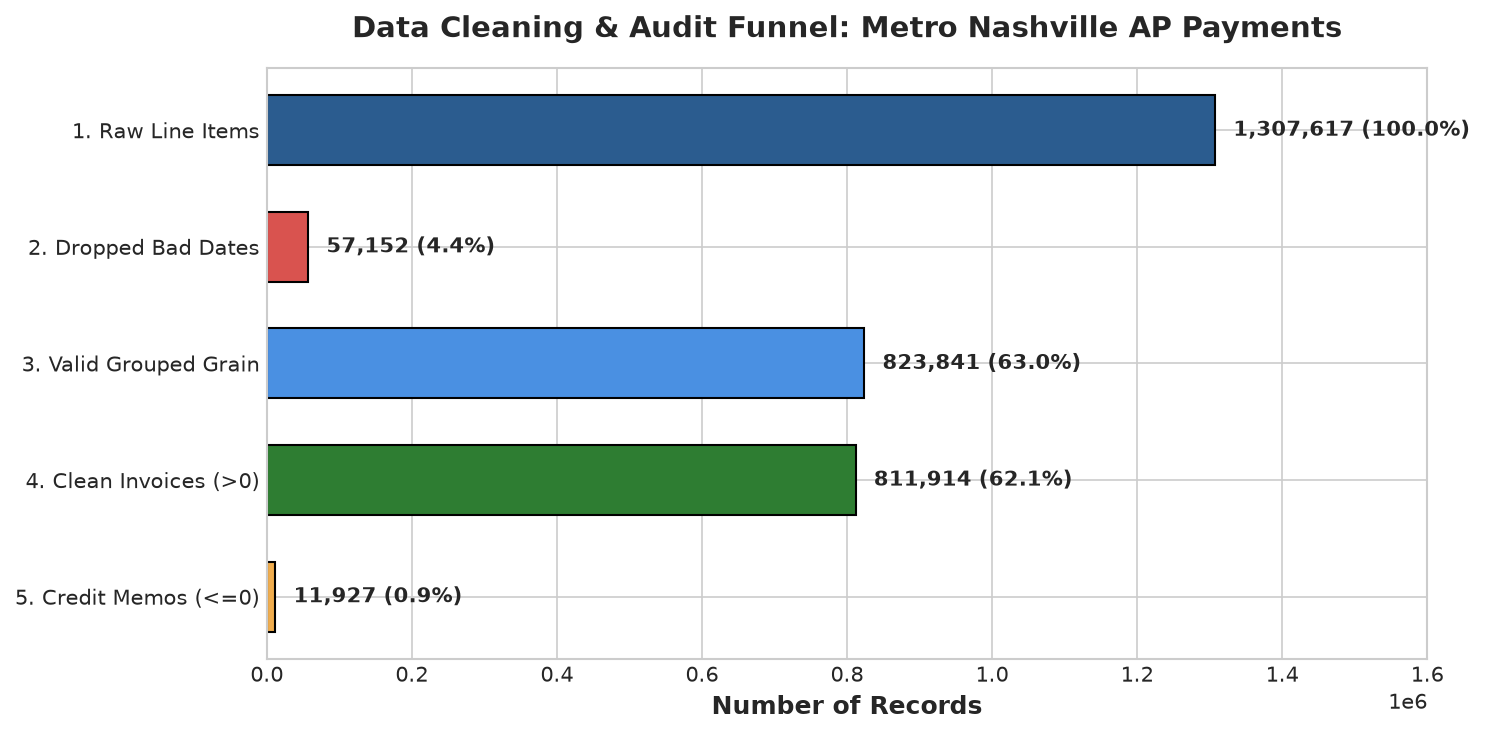

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\01_data_audit_funnel.png


In [2]:
audit_json_path = SETTINGS.interim_dir / "invoices_audit_summary.json"
with open(audit_json_path, "r", encoding="utf-8") as f:
    audit_summary = json.load(f)

print("Audited Summary Metrics:")
for k, v in audit_summary.items():
    print(f"  {k:25s}: {v:>12,d}")

# Create summary DataFrame for visualization
funnel_data = [
    {"Stage": "1. Raw Line Items", "Count": audit_summary["raw_rows"], "Pct_Raw": 100.0, "Type": "Raw"},
    {"Stage": "2. Dropped Bad Dates", "Count": audit_summary["dropped_bad_dates"], "Pct_Raw": audit_summary["dropped_bad_dates"] / audit_summary["raw_rows"] * 100, "Type": "Dropped"},
    {"Stage": "3. Valid Grouped Grain", "Count": audit_summary["grouped_rows"], "Pct_Raw": audit_summary["grouped_rows"] / audit_summary["raw_rows"] * 100, "Type": "Aggregated"},
    {"Stage": "4. Clean Invoices (>0)", "Count": audit_summary["clean_invoice_rows"], "Pct_Raw": audit_summary["clean_invoice_rows"] / audit_summary["raw_rows"] * 100, "Type": "Clean"},
    {"Stage": "5. Credit Memos (<=0)", "Count": audit_summary["credit_memo_rows"], "Pct_Raw": audit_summary["credit_memo_rows"] / audit_summary["raw_rows"] * 100, "Type": "Segregated"},
]
df_funnel = pd.DataFrame(funnel_data)
display(df_funnel)

# Plot Data Audit Funnel
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2b5c8f", "#d9534f", "#4a90e2", "#2e7d32", "#f0ad4e"]
bars = ax.barh(df_funnel["Stage"][::-1], df_funnel["Count"][::-1], color=colors[::-1], edgecolor="black", height=0.6)

for bar in bars:
    width = bar.get_width()
    pct = (width / audit_summary["raw_rows"]) * 100
    ax.text(width + 25000, bar.get_y() + bar.get_height()/2, 
            f"{int(width):,d} ({pct:.1f}%)", 
            va='center', ha='left', fontsize=10, fontweight='bold')

ax.set_xlim(0, 1600000)
ax.set_xlabel("Number of Records")
ax.set_title("Data Cleaning & Audit Funnel: Metro Nashville AP Payments", pad=15)
plt.tight_layout()
fig_funnel_path = eda_artifacts_dir / "01_data_audit_funnel.png"
fig.savefig(fig_funnel_path, dpi=300)
plt.show()
print(f"Saved: {fig_funnel_path}")

---
## Section 2: Distribution & Skewness Profiling (`days_to_pay` & `invoice_amount`)
In financial accounts payable data, operational metrics rarely follow normal (Gaussian) distributions.
We systematically compute:
1. Parametric metrics: Mean, Standard Deviation, Skewness, Kurtosis.
2. Non-parametric robust metrics: Min, p25, Median (p50), p75, Interquartile Range (IQR), p90, p95, p99, Max.

**Key Mathematical Insights:**
- If Skewness $> 1$, distribution has a pronounced right tail; the mean is pulled rightward by extreme outliers.
- Standard payment terms (e.g., Net 30) generate high probability mass spikes at exactly 30 days.

Loaded clean invoices: 811,914 rows, 14 columns


Metric / Column,days_to_pay,invoice_amount
Mean,37.37,"15,943.75"
Std,52.21,"292,783.34"
Skewness,13.30,98.56
Kurtosis,338.99,"14,976.79"
Min,0.00,0.01
p25,27.00,127.00
Median (p50),30.00,385.71
p75,30.00,"1,700.00"
IQR,3.00,"1,573.00"
p90,61.00,"8,059.96"


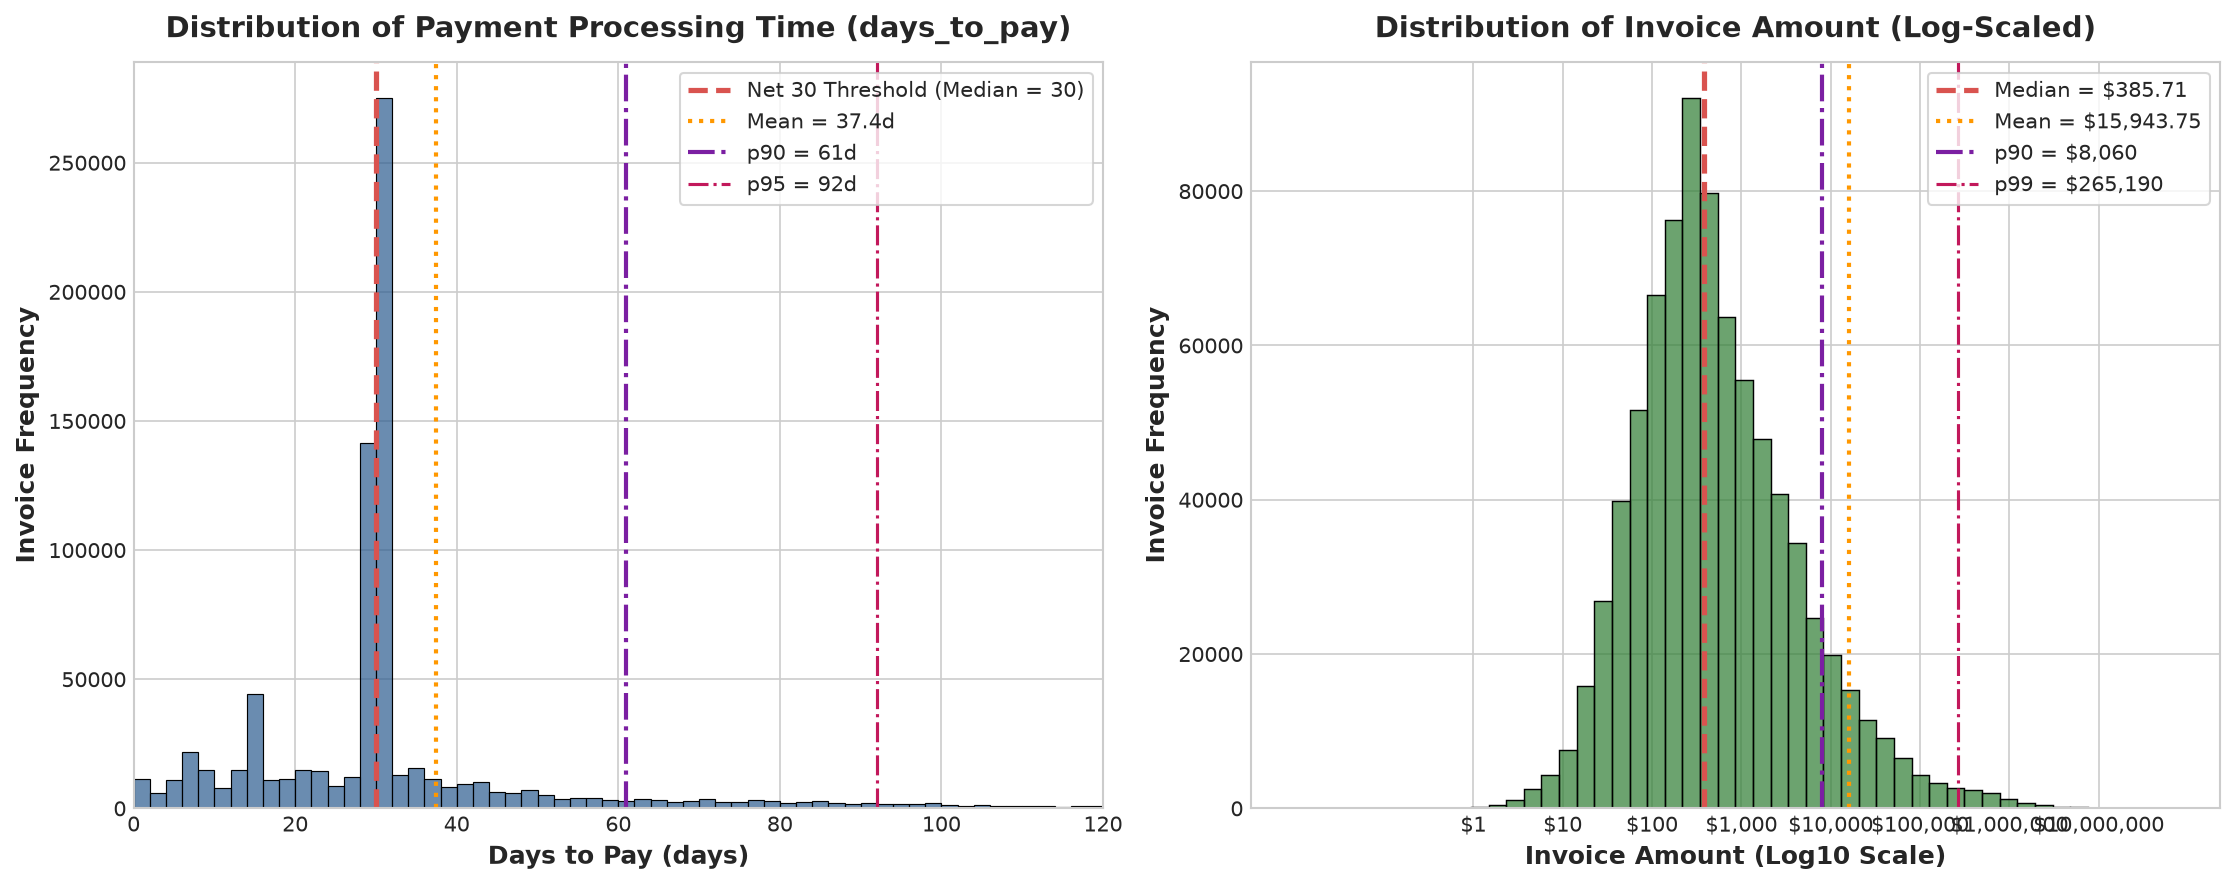

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\02_distributions_skew.png


In [3]:
clean_parquet_path = SETTINGS.interim_dir / "invoices_clean.parquet"
df = pd.read_parquet(clean_parquet_path)
print(f"Loaded clean invoices: {len(df):,d} rows, {df.shape[1]} columns")

metrics_summary = []
for col in ["days_to_pay", "invoice_amount"]:
    s = df[col]
    q = s.quantile([0.0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]).to_dict()
    iqr = q[0.75] - q[0.25]
    metrics_summary.append({
        "Metric / Column": col,
        "Mean": s.mean(),
        "Std": s.std(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis(),
        "Min": q[0.0],
        "p25": q[0.25],
        "Median (p50)": q[0.50],
        "p75": q[0.75],
        "IQR": iqr,
        "p90": q[0.90],
        "p95": q[0.95],
        "p99": q[0.99],
        "Max": q[1.0]
    })

df_metrics = pd.DataFrame(metrics_summary).set_index("Metric / Column").T
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
display(df_metrics)

# Visualizing Distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: days_to_pay (zoomed to 0-120 days to show Net 30 spike and tail)
ax_days = axes[0]
sns.histplot(df["days_to_pay"], bins=np.arange(0, 125, 2), ax=ax_days, color="#2b5c8f", edgecolor="black", alpha=0.7)
ax_days.axvline(30, color="#d9534f", linestyle="--", linewidth=2.5, label="Net 30 Threshold (Median = 30)")
ax_days.axvline(df["days_to_pay"].mean(), color="#ff9800", linestyle=":", linewidth=2, label=f"Mean = {df['days_to_pay'].mean():.1f}d")
ax_days.axvline(61, color="#7b1fa2", linestyle="-.", linewidth=2, label="p90 = 61d")
ax_days.axvline(92, color="#c2185b", linestyle="-.", linewidth=1.5, label="p95 = 92d")
ax_days.set_xlim(0, 120)
ax_days.set_xlabel("Days to Pay (days)")
ax_days.set_ylabel("Invoice Frequency")
ax_days.set_title("Distribution of Payment Processing Time (days_to_pay)", pad=12)
ax_days.legend(loc="upper right", frameon=True)

# Panel B: invoice_amount (Log scale distribution)
ax_amt = axes[1]
log_amounts = np.log10(df["invoice_amount"])
sns.histplot(log_amounts, bins=50, ax=ax_amt, color="#2e7d32", edgecolor="black", alpha=0.7)
median_amt = df["invoice_amount"].median()
mean_amt = df["invoice_amount"].mean()
ax_amt.axvline(np.log10(median_amt), color="#d9534f", linestyle="--", linewidth=2.5, label=f"Median = ${median_amt:,.2f}")
ax_amt.axvline(np.log10(mean_amt), color="#ff9800", linestyle=":", linewidth=2, label=f"Mean = ${mean_amt:,.2f}")
ax_amt.axvline(np.log10(8059.96), color="#7b1fa2", linestyle="-.", linewidth=2, label="p90 = $8,060")
ax_amt.axvline(np.log10(265189.87), color="#c2185b", linestyle="-.", linewidth=1.5, label="p99 = $265,190")

# Format ticks as dollar values
ticks_loc = np.arange(0, 8, 1)
ax_amt.set_xticks(ticks_loc)
ax_amt.set_xticklabels([f"${10**t:,.0f}" for t in ticks_loc])
ax_amt.set_xlabel("Invoice Amount (Log10 Scale)")
ax_amt.set_ylabel("Invoice Frequency")
ax_amt.set_title("Distribution of Invoice Amount (Log-Scaled)", pad=12)
ax_amt.legend(loc="upper right", frameon=True)

plt.tight_layout()
fig_dist_path = eda_artifacts_dir / "02_distributions_skew.png"
fig.savefig(fig_dist_path, dpi=300)
plt.show()
print(f"Saved: {fig_dist_path}")

---
## Section 3: Right-Censoring Bias Empirical Verification
A fundamental risk in Accounts Payable modeling is **Right-Censoring Bias**.
Because the dataset is collected at a fixed point in time (`max(Payment_Date) = 2025-12-31`), invoices issued near the cutoff date have had insufficient calendar time to be settled:
- An invoice issued in December 2025 can at most record `days_to_pay <= 31`.
- Any invoice issued in December that takes $> 30$ days to pay has **not yet been paid**, and therefore is omitted from the paid transactions ledger.
- This creates an artificial collapse in observed payment delays and observed late rates in late 2025!

**Buffer Calculation:**
- Across all $811,914$ clean invoices, the 90th percentile of `days_to_pay` is **$61.0$ days** (only $10.08\%$ take $> 60$ days).
- By terminating the test period at `test_end = 2025-10-31`, we enforce an exact **$61$-day buffer** (November 1 through December 31 = 61 days) before data cutoff.
- This guarantees that $\ge 90\%$ of invoices issued up to October 31 had complete opportunity to be paid and observed without truncation distortion.

Monthly 2025 Dynamics & Truncation Impact:


,inv_year_month,n_invoices,median_days,mean_days,p90_days,late_rate_30
0,2025-01,20513,30.00,32.11,48.00,0.17
1,2025-02,19003,30.00,33.02,49.00,0.22
2,2025-03,20405,30.00,32.46,50.00,0.22
3,2025-04,23359,30.00,32.25,48.00,0.25
4,2025-05,20766,30.00,32.56,48.00,0.37
5,2025-06,15031,29.00,28.34,40.00,0.20
6,2025-07,15405,30.00,28.77,40.00,0.16
7,2025-08,20526,30.00,29.24,36.00,0.13
8,2025-09,20582,30.00,28.92,42.00,0.17
9,2025-10,20299,29.00,27.39,38.00,0.16


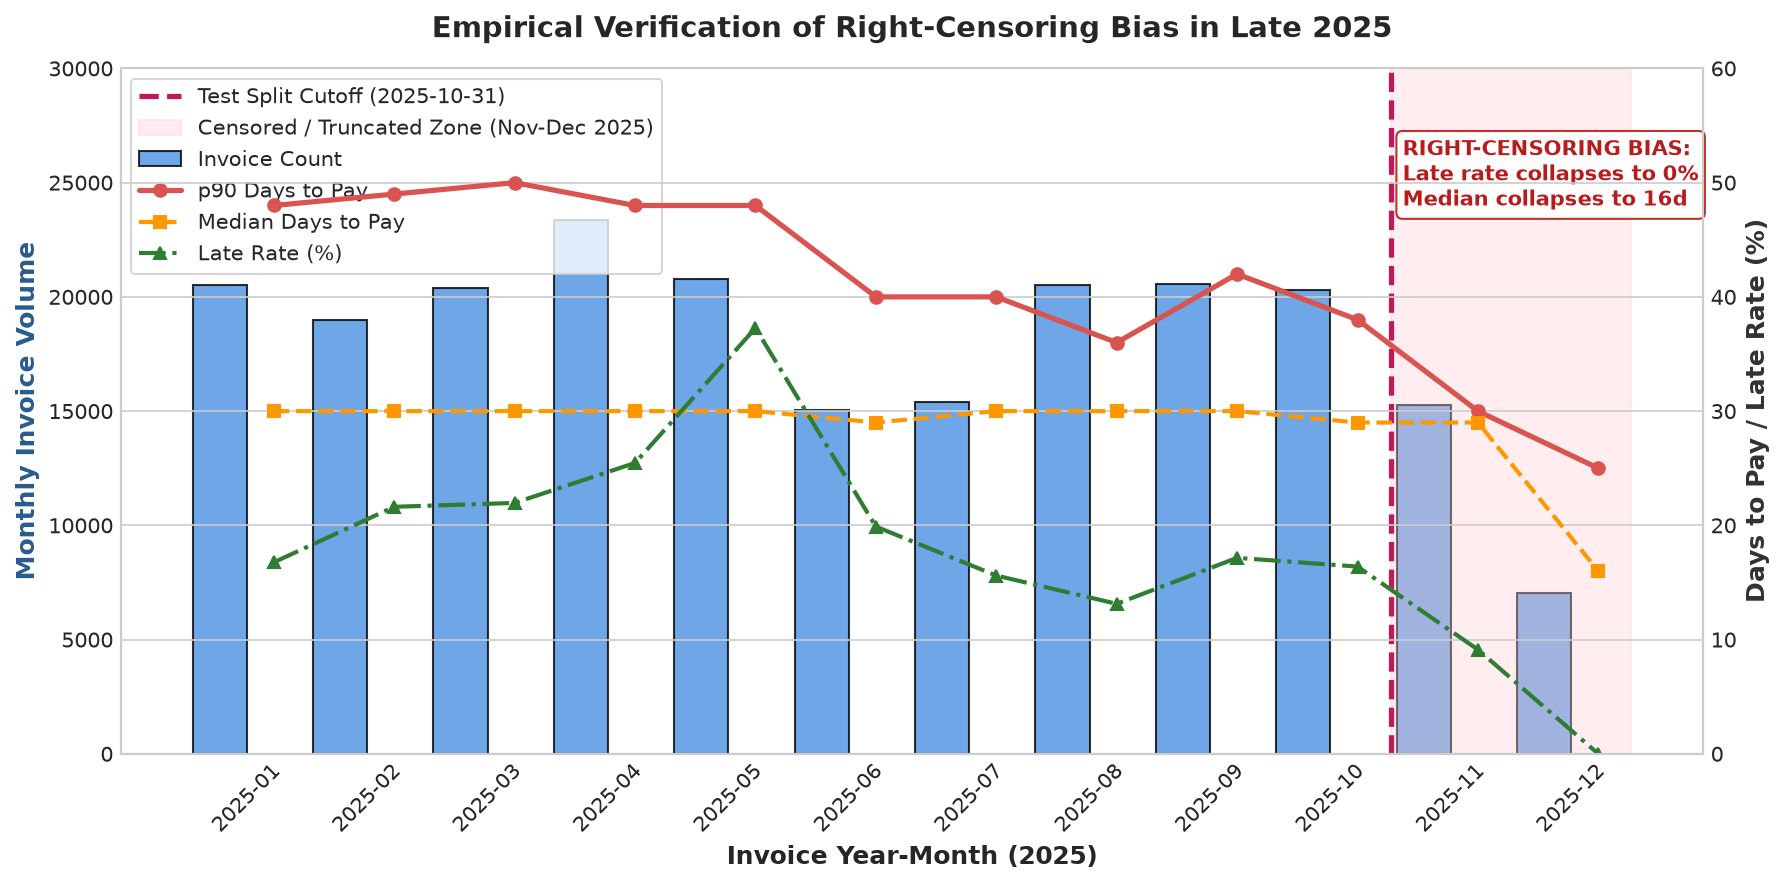

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\03_right_censoring_verification.png


In [4]:
# Extract month of invoice date
df["inv_year_month"] = pd.to_datetime(df["invoice_date"]).dt.to_period("M").astype(str)

monthly_2025 = df[df["inv_year_month"].str.startswith("2025")].groupby("inv_year_month").agg(
    n_invoices=("invoice_number", "count"),
    median_days=("days_to_pay", "median"),
    mean_days=("days_to_pay", "mean"),
    p90_days=("days_to_pay", lambda x: np.percentile(x, 90)),
    late_rate_30=("is_late", "mean")
).reset_index()

print("Monthly 2025 Dynamics & Truncation Impact:")
display(monthly_2025)

# Visualizing Right-Censoring Distortion
fig, ax1 = plt.subplots(figsize=(12, 6))

x = np.arange(len(monthly_2025))
width = 0.45

# Plot Invoice Count on primary axis
bars = ax1.bar(x - width/2, monthly_2025["n_invoices"], width=width, color="#4a90e2", alpha=0.8, edgecolor="black", label="Invoice Count")
ax1.set_ylabel("Monthly Invoice Volume", color="#2b5c8f", fontweight="bold")
ax1.set_ylim(0, 30000)
ax1.grid(False)

# Secondary axis for days_to_pay and late rate
ax2 = ax1.twinx()
line_p90 = ax2.plot(x + width/2, monthly_2025["p90_days"], color="#d9534f", marker="o", linewidth=2.5, label="p90 Days to Pay")
line_median = ax2.plot(x + width/2, monthly_2025["median_days"], color="#ff9800", marker="s", linewidth=2, linestyle="--", label="Median Days to Pay")
line_late = ax2.plot(x + width/2, monthly_2025["late_rate_30"] * 100, color="#2e7d32", marker="^", linewidth=2, linestyle="-.", label="Late Rate (%)")

ax2.set_ylabel("Days to Pay / Late Rate (%)", color="#333333", fontweight="bold")
ax2.set_ylim(0, 60)

# Mark the test split cutoff boundary (2025-10-31, index 9)
cutoff_idx = monthly_2025[monthly_2025["inv_year_month"] == "2025-10"].index[0]
ax1.axvline(cutoff_idx + 0.5, color="#c2185b", linestyle="--", linewidth=2.5, label="Test Split Cutoff (2025-10-31)")

# Annotate Right-Censoring Zone
ax1.axvspan(cutoff_idx + 0.5, len(monthly_2025) - 0.5, color="#ffcdd2", alpha=0.35, label="Censored / Truncated Zone (Nov-Dec 2025)")
ax1.text(cutoff_idx + 0.6, 24000, "RIGHT-CENSORING BIAS:\nLate rate collapses to 0%\nMedian collapses to 16d", 
         color="#b71c1c", fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#b71c1c", alpha=0.9))

ax1.set_xticks(x)
ax1.set_xticklabels(monthly_2025["inv_year_month"], rotation=45)
ax1.set_xlabel("Invoice Year-Month (2025)")
ax1.set_title("Empirical Verification of Right-Censoring Bias in Late 2025", pad=15)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)

plt.tight_layout()
fig_rc_path = eda_artifacts_dir / "03_right_censoring_verification.png"
fig.savefig(fig_rc_path, dpi=300)
plt.show()
print(f"Saved: {fig_rc_path}")

---
## Section 4: Late Rate Threshold Sensitivity & Fiscal Seasonality
In Accounts Payable management, the definition of what constitutes a 'late' invoice has significant operational implications:
1. **Net 30**: Benchmark standard under prompt payment statutes (30 calendar days).
2. **Net 45**: Grace period extended by certain procurement contracts.
3. **Net 60**: Serious operational delinquency.

Furthermore, governmental organizations exhibit strong budgetary calendar cycles. Metro Nashville's Fiscal Year begins July 1 and ends **June 30**. We investigate whether invoice arrival month systematically impacts late payment rates.

,Threshold (Days),Late Invoices,Late Rate (%),Operational Interpretation
0,>15 days,679689,83.71,Severe Penalty
1,>30 days,201026,24.76,Prompt Payment Net 30
2,>45 days,116958,14.41,Grace Net 45
3,>60 days,81870,10.08,Delinquent
4,>90 days,41836,5.15,Delinquent


,Month_Name,n_invoices,late_rate_30,median_days,mean_days
0,Jan,57959,24.58,30.00,40.45
1,Feb,59575,25.73,30.00,40.28
2,Mar,63593,26.88,30.00,40.24
3,Apr,69665,30.45,30.00,40.06
4,May,65335,37.27,30.00,38.70
5,Jun,60448,22.18,30.00,35.26
6,Jul,60693,19.48,30.00,35.80
7,Aug,86234,18.44,30.00,34.52
8,Sep,80617,21.28,30.00,34.84
9,Oct,80776,22.81,30.00,36.37


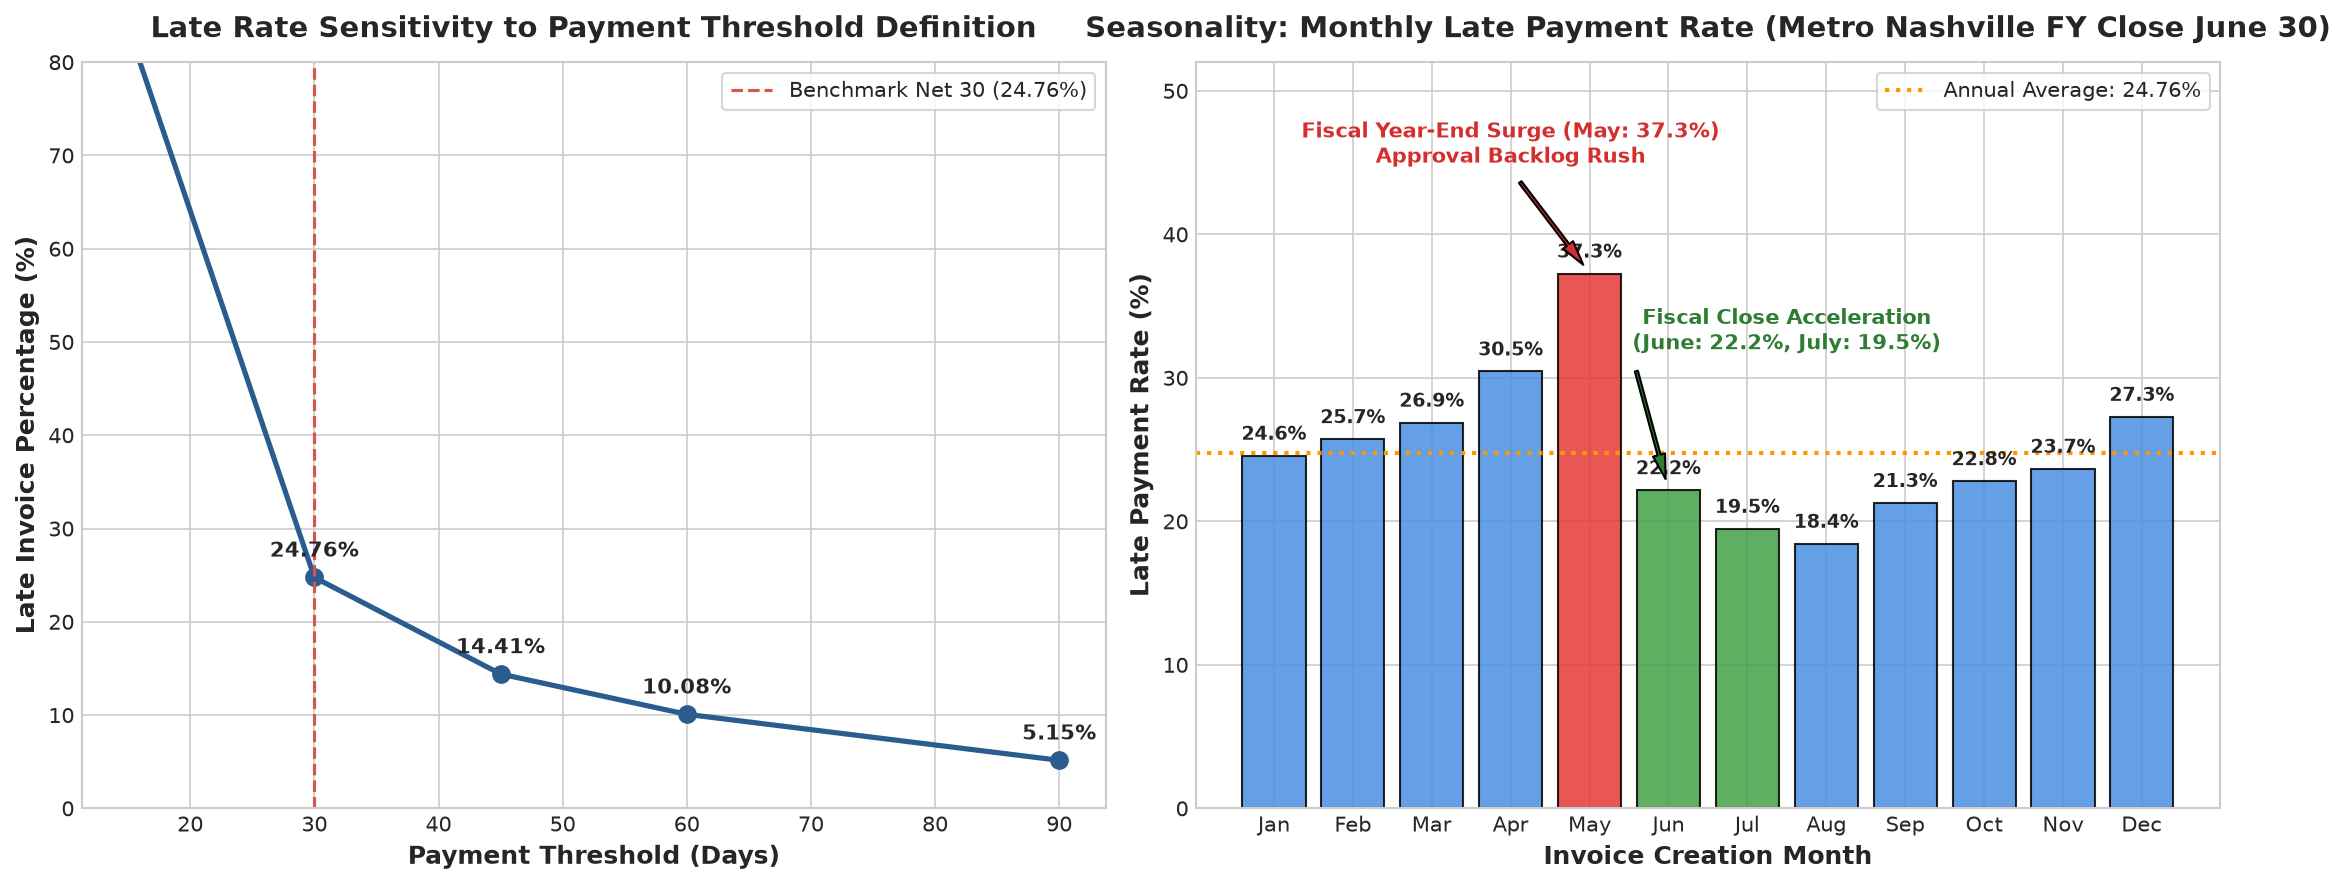

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\04_threshold_and_seasonality.png


In [5]:
# Threshold sensitivity calculation
thresholds = [15, 30, 45, 60, 90]
sensitivity_results = []
for t in thresholds:
    count_late = (df["days_to_pay"] > t).sum()
    pct_late = count_late / len(df) * 100
    sensitivity_results.append({
        "Threshold (Days)": f">{t} days",
        "Late Invoices": count_late,
        "Late Rate (%)": pct_late,
        "Operational Interpretation": "Severe Penalty" if t==15 else ("Prompt Payment Net 30" if t==30 else ("Grace Net 45" if t==45 else "Delinquent"))
    })

df_sensitivity = pd.DataFrame(sensitivity_results)
display(df_sensitivity)

# Fiscal seasonality across 12 calendar months
df["inv_month"] = pd.to_datetime(df["invoice_date"]).dt.month
monthly_seasonality = df.groupby("inv_month").agg(
    n_invoices=("invoice_number", "count"),
    late_rate_30=("is_late", lambda x: np.mean(x) * 100),
    median_days=("days_to_pay", "median"),
    mean_days=("days_to_pay", "mean")
).reset_index()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_seasonality["Month_Name"] = [month_names[m-1] for m in monthly_seasonality["inv_month"]]
display(monthly_seasonality[["Month_Name", "n_invoices", "late_rate_30", "median_days", "mean_days"]])

# Plotting Threshold Sensitivity & Fiscal Seasonality
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Threshold Sensitivity Curve
ax_sens = axes[0]
t_vals = [15, 30, 45, 60, 90]
rates = [df_sensitivity.loc[df_sensitivity["Threshold (Days)"]==f">{t} days", "Late Rate (%)"].values[0] for t in t_vals]
ax_sens.plot(t_vals, rates, marker="o", color="#2b5c8f", linewidth=2.5, markersize=8)
for x_val, y_val in zip(t_vals, rates):
    ax_sens.annotate(f"{y_val:.2f}%", (x_val, y_val), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
ax_sens.axvline(30, color="#d9534f", linestyle="--", label="Benchmark Net 30 (24.76%)")
ax_sens.set_xlabel("Payment Threshold (Days)")
ax_sens.set_ylabel("Late Invoice Percentage (%)")
ax_sens.set_title("Late Rate Sensitivity to Payment Threshold Definition", pad=12)
ax_sens.set_ylim(0, 80)
ax_sens.legend(loc="upper right", frameon=True)

# Panel B: Fiscal Year-End Seasonality
ax_seas = axes[1]
bars = ax_seas.bar(monthly_seasonality["Month_Name"], monthly_seasonality["late_rate_30"], 
                   color=["#4a90e2" if m not in [5, 6, 7] else ("#e53935" if m==5 else "#43a047") for m in monthly_seasonality["inv_month"]],
                   edgecolor="black", alpha=0.85)

for bar in bars:
    height = bar.get_height()
    ax_seas.text(bar.get_x() + bar.get_width()/2, height + 0.8, f"{height:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax_seas.axhline(df["is_late"].mean() * 100, color="#ff9800", linestyle=":", linewidth=2, label=f"Annual Average: {df['is_late'].mean()*100:.2f}%")
ax_seas.annotate("Fiscal Year-End Surge (May: 37.3%)\nApproval Backlog Rush", 
                 xy=(4, 37.3), xytext=(3, 45),
                 arrowprops=dict(facecolor='#d32f2f', shrink=0.08, width=1.5, headwidth=6),
                 fontweight="bold", color="#d32f2f", ha="center")
ax_seas.annotate("Fiscal Close Acceleration\n(June: 22.2%, July: 19.5%)", 
                 xy=(5, 22.2), xytext=(6.5, 32),
                 arrowprops=dict(facecolor='#2e7d32', shrink=0.08, width=1.5, headwidth=6),
                 fontweight="bold", color="#2e7d32", ha="center")

ax_seas.set_xlabel("Invoice Creation Month")
ax_seas.set_ylabel("Late Payment Rate (%)")
ax_seas.set_title("Seasonality: Monthly Late Payment Rate (Metro Nashville FY Close June 30)", pad=12)
ax_seas.set_ylim(0, 52)
ax_seas.legend(loc="upper right", frameon=True)

plt.tight_layout()
fig_seas_path = eda_artifacts_dir / "04_threshold_and_seasonality.png"
fig.savefig(fig_seas_path, dpi=300)
plt.show()
print(f"Saved: {fig_seas_path}")

---
## Section 5: Formal Statistical Hypothesis Testing
To transition from descriptive exploration to statistically grounded inference, we test 4 structural hypotheses:
1. **Hypothesis 1 (Multi-Department Routing)**:
   - $H_0$: Invoices split across multiple departments (`dept_count > 1`) follow the same `days_to_pay` distribution as single-department invoices.
   - $H_1$: Multi-department routing alters payment turnaround.
   - *Test*: Mann-Whitney U test (non-parametric rank-sum test due to severe non-normality).
2. **Hypothesis 2 (Invoice Value Prioritization)**:
   - $H_0$: High-value invoices ($> 75$th percentile, $\$1,700$) have the same payment turnaround as normal-value invoices.
   - $H_1$: High-value invoices face different processing speed (scrutiny vs priority).
   - *Test*: Mann-Whitney U test.
3. **Hypothesis 3 (Fiscal Close Seasonality)**:
   - $H_0$: Invoices created in June (Fiscal Year-End Close) have the same late rate as other months.
   - $H_1$: June late rate differs significantly from the annual baseline.
   - *Test*: Pearson's Chi-Square Contingency Test ($2 \times 2$).
4. **Hypothesis 4 (Operating Unit Disparity)**:
   - $H_0$: Operating units (`METRO_GG` vs `METRO_MNPS`) have identical late payment rates.
   - $H_1$: Late rates differ significantly by administrative governance structure.
   - *Test*: Pearson's Chi-Square Contingency Test ($2 \times 2$).

**Effect Size Formulation:**
- For Mann-Whitney U: $r = \frac{|z|}{\sqrt{N}}$, where $z = \frac{U - \mu_U}{\sigma_U}$, $N = n_1 + n_2$.
- For Chi-Square: Cramér's $V = \sqrt{\frac{\chi^2}{N \cdot (k - 1)}}$.

,Hypothesis Test,Test Statistic,p-value,Effect Size,Decision
0,1. Multi-Dept vs Single-Dept (days_to_pay),"U=664,699,538 (z=-9.72)",4.2883e-23,r = 0.0108 (Small),Reject H0 (p < 0.001)
1,2. High-Value vs Normal-Value (days_to_pay),"U=57,883,994,058 (z=-42.57)",0.0000e+00,r = 0.0472 (Small),Reject H0 (p < 0.001)
2,3. June Fiscal Close vs Other (is_late),Chi2 = 233.83,8.6999e-53,V = 0.0170 (Small),Reject H0 (p < 0.001)
3,4. Operating Units: GG vs MNPS (is_late),"Chi2 = 13,700.04",0.0000e+00,V = 0.1299 (Moderate),Reject H0 (p < 0.001)


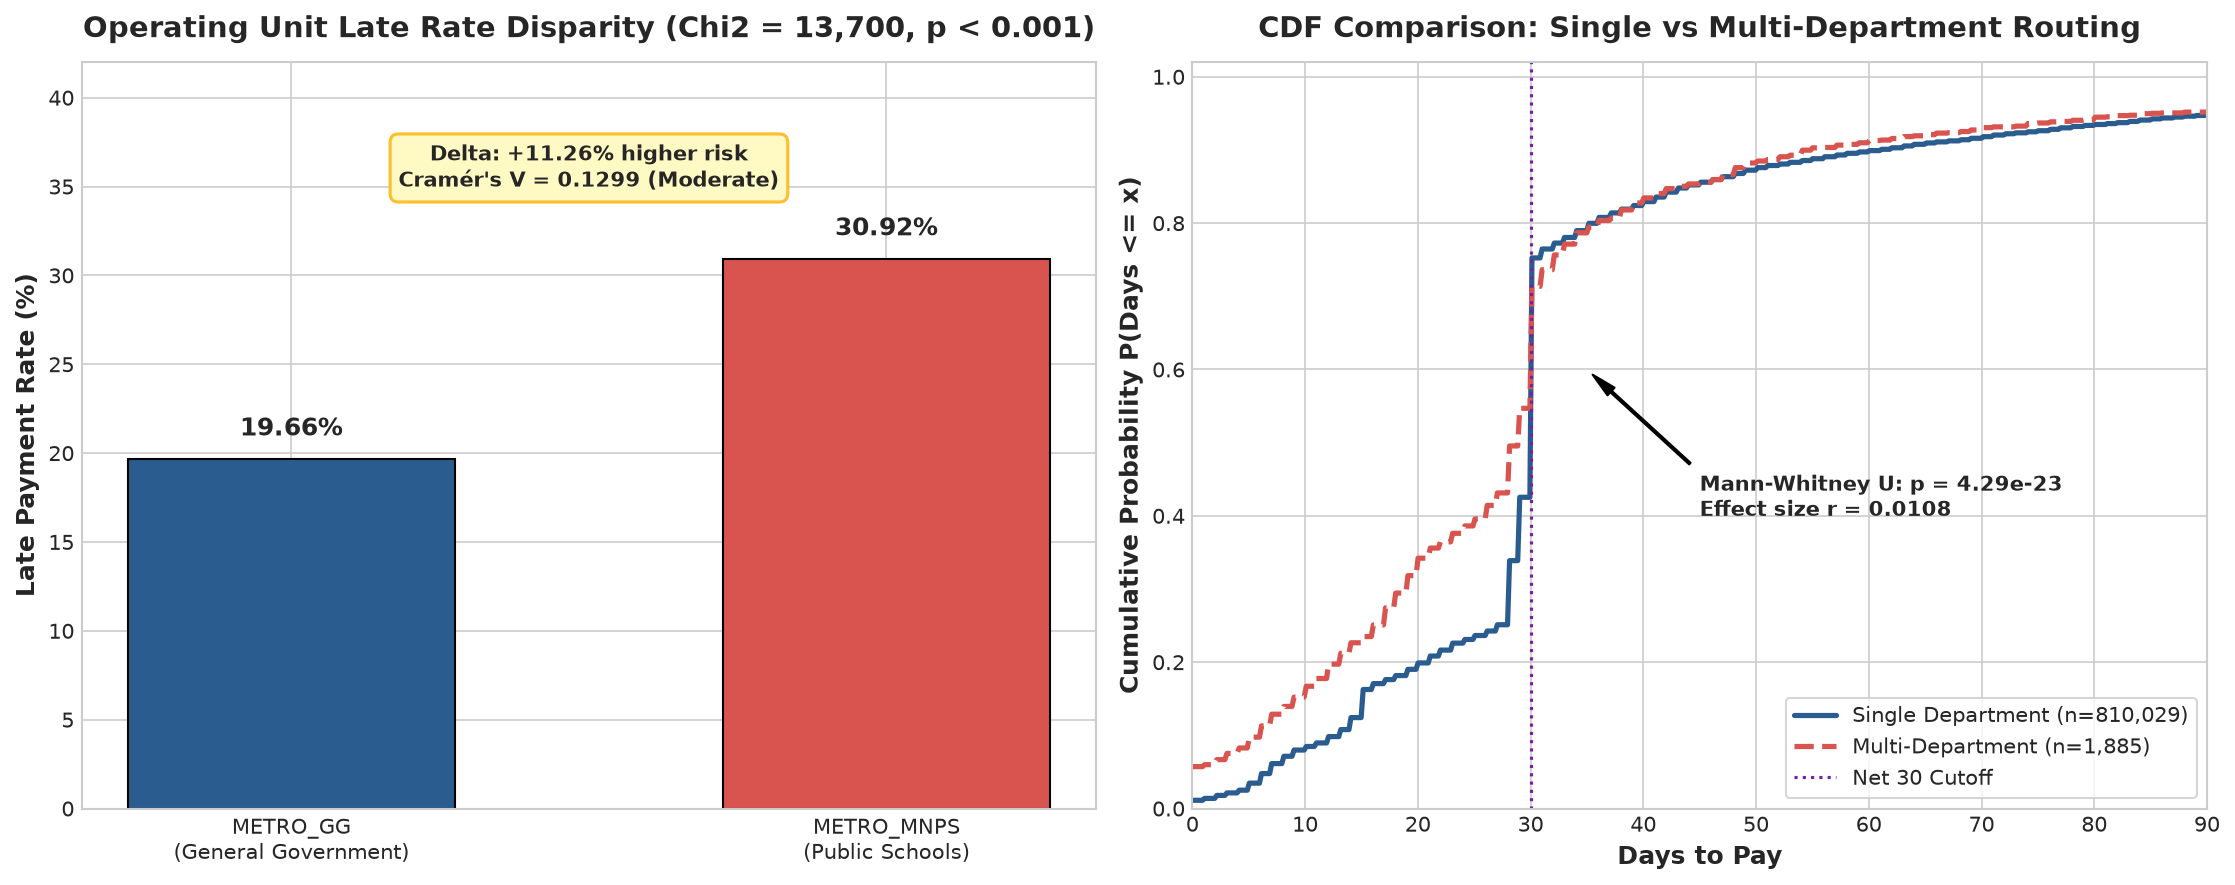

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\05_hypothesis_tests.png


In [6]:
# Test 1: Multi-department vs Single-department
single_dept_days = df[df["dept_count"] == 1]["days_to_pay"]
multi_dept_days = df[df["dept_count"] > 1]["days_to_pay"]
mwu_dept = stats.mannwhitneyu(multi_dept_days, single_dept_days, alternative="two-sided")
n1, n2 = len(multi_dept_days), len(single_dept_days)
m_u = n1 * n2 / 2
sigma_u = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
z_dept = (mwu_dept.statistic - m_u) / sigma_u
r_dept = abs(z_dept) / np.sqrt(n1 + n2)

# Test 2: High-value vs Normal-value
p75_val = df["invoice_amount"].quantile(0.75)
high_val_days = df[df["invoice_amount"] > p75_val]["days_to_pay"]
norm_val_days = df[df["invoice_amount"] <= p75_val]["days_to_pay"]
mwu_val = stats.mannwhitneyu(high_val_days, norm_val_days, alternative="two-sided")
n1_val, n2_val = len(high_val_days), len(norm_val_days)
m_u_val = n1_val * n2_val / 2
sigma_u_val = np.sqrt(n1_val * n2_val * (n1_val + n2_val + 1) / 12)
z_val = (mwu_val.statistic - m_u_val) / sigma_u_val
r_val = abs(z_val) / np.sqrt(n1_val + n2_val)

# Test 3: June Fiscal Close vs Normal Months
is_june = df["inv_month"] == 6
table_june = pd.crosstab(is_june, df["is_late"])
chi2_june, p_june, dof_june, _ = stats.chi2_contingency(table_june)
cramers_v_june = np.sqrt(chi2_june / (len(df) * (min(table_june.shape) - 1)))

# Test 4: Operating Units
table_ou = pd.crosstab(df["operating_unit"], df["is_late"])
chi2_ou, p_ou, dof_ou, _ = stats.chi2_contingency(table_ou)
cramers_v_ou = np.sqrt(chi2_ou / (len(df) * (min(table_ou.shape) - 1)))

hypothesis_summary = [
    {
        "Hypothesis Test": "1. Multi-Dept vs Single-Dept (days_to_pay)",
        "Sample Sizes": f"n1={n1:,d}, n2={n2:,d}",
        "Group 1 (Obs)": f"Median: {multi_dept_days.median():.0f}d, Mean: {multi_dept_days.mean():.2f}d",
        "Group 2 (Obs)": f"Median: {single_dept_days.median():.0f}d, Mean: {single_dept_days.mean():.2f}d",
        "Test Statistic": f"U={mwu_dept.statistic:,.0f} (z={z_dept:.2f})",
        "p-value": f"{mwu_dept.pvalue:.4e}",
        "Effect Size": f"r = {r_dept:.4f} (Small)",
        "Decision": "Reject H0 (p < 0.001)"
    },
    {
        "Hypothesis Test": "2. High-Value vs Normal-Value (days_to_pay)",
        "Sample Sizes": f"n1={n1_val:,d}, n2={n2_val:,d}",
        "Group 1 (Obs)": f"Median: {high_val_days.median():.0f}d, Mean: {high_val_days.mean():.2f}d",
        "Group 2 (Obs)": f"Median: {norm_val_days.median():.0f}d, Mean: {norm_val_days.mean():.2f}d",
        "Test Statistic": f"U={mwu_val.statistic:,.0f} (z={z_val:.2f})",
        "p-value": f"{mwu_val.pvalue:.4e}",
        "Effect Size": f"r = {r_val:.4f} (Small)",
        "Decision": "Reject H0 (p < 0.001)"
    },
    {
        "Hypothesis Test": "3. June Fiscal Close vs Other (is_late)",
        "Sample Sizes": f"June={table_june.loc[True].sum():,d}, Other={table_june.loc[False].sum():,d}",
        "Group 1 (Obs)": f"Late: {df[df['inv_month']==6]['is_late'].mean()*100:.2f}%",
        "Group 2 (Obs)": f"Late: {df[df['inv_month']!=6]['is_late'].mean()*100:.2f}%",
        "Test Statistic": f"Chi2 = {chi2_june:,.2f}",
        "p-value": f"{p_june:.4e}",
        "Effect Size": f"V = {cramers_v_june:.4f} (Small)",
        "Decision": "Reject H0 (p < 0.001)"
    },
    {
        "Hypothesis Test": "4. Operating Units: GG vs MNPS (is_late)",
        "Sample Sizes": f"GG={table_ou.loc['METRO_GG'].sum():,d}, MNPS={table_ou.loc['METRO_MNPS'].sum():,d}",
        "Group 1 (Obs)": f"Late: {df[df['operating_unit']=='METRO_GG']['is_late'].mean()*100:.2f}%",
        "Group 2 (Obs)": f"Late: {df[df['operating_unit']=='METRO_MNPS']['is_late'].mean()*100:.2f}%",
        "Test Statistic": f"Chi2 = {chi2_ou:,.2f}",
        "p-value": f"{p_ou:.4e}",
        "Effect Size": f"V = {cramers_v_ou:.4f} (Moderate)",
        "Decision": "Reject H0 (p < 0.001)"
    }
]

df_tests = pd.DataFrame(hypothesis_summary)
display(df_tests[["Hypothesis Test", "Test Statistic", "p-value", "Effect Size", "Decision"]])

# Plotting Hypothesis Test Comparisons
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Operating Unit Disparity (Chi-Square)
ax_ou = axes[0]
ou_rates = df.groupby("operating_unit")["is_late"].mean() * 100
bars_ou = ax_ou.bar(["METRO_GG\n(General Government)", "METRO_MNPS\n(Public Schools)"], 
                    [ou_rates["METRO_GG"], ou_rates["METRO_MNPS"]],
                    color=["#2b5c8f", "#d9534f"], edgecolor="black", width=0.55)

for bar in bars_ou:
    h = bar.get_height()
    ax_ou.text(bar.get_x() + bar.get_width()/2, h + 1.0, f"{h:.2f}%", ha='center', va='bottom', fontsize=12, fontweight='bold')

ax_ou.set_ylabel("Late Payment Rate (%)")
ax_ou.set_ylim(0, 42)
ax_ou.set_title("Operating Unit Late Rate Disparity (Chi2 = 13,700, p < 0.001)", pad=12)
ax_ou.annotate(f"Delta: +{ou_rates['METRO_MNPS'] - ou_rates['METRO_GG']:.2f}% higher risk\nCramér's V = 0.1299 (Moderate)", 
              xy=(0.5, 25), xytext=(0.5, 35),
              ha="center", fontsize=10, fontweight="bold",
              bbox=dict(boxstyle="round,pad=0.4", fc="#fff9c4", ec="#fbc02d", lw=1.5))

# Panel B: Cumulative Distribution Function (CDF) of days_to_pay: Multi-dept vs Single-dept
ax_cdf = axes[1]
x_eval = np.linspace(0, 90, 500)
cdf_single = [np.mean(single_dept_days <= val) for val in x_eval]
cdf_multi = [np.mean(multi_dept_days <= val) for val in x_eval]

ax_cdf.plot(x_eval, cdf_single, color="#2b5c8f", linewidth=2.5, label="Single Department (n=810,029)")
ax_cdf.plot(x_eval, cdf_multi, color="#d9534f", linewidth=2.5, linestyle="--", label="Multi-Department (n=1,885)")
ax_cdf.axvline(30, color="#7b1fa2", linestyle=":", label="Net 30 Cutoff")
ax_cdf.set_xlabel("Days to Pay")
ax_cdf.set_ylabel("Cumulative Probability P(Days <= x)")
ax_cdf.set_title("CDF Comparison: Single vs Multi-Department Routing", pad=12)
ax_cdf.set_xlim(0, 90)
ax_cdf.set_ylim(0, 1.02)
ax_cdf.legend(loc="lower right", frameon=True)
ax_cdf.annotate(f"Mann-Whitney U: p = 4.29e-23\nEffect size r = 0.0108", 
               xy=(35, 0.6), xytext=(45, 0.4),
               arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
               fontweight="bold")

plt.tight_layout()
fig_hypo_path = eda_artifacts_dir / "05_hypothesis_tests.png"
fig.savefig(fig_hypo_path, dpi=300)
plt.show()
print(f"Saved: {fig_hypo_path}")

---
## Section 6: Vendor Concentration & Pareto Analysis
Financial accounts payable portfolios are characteristically subject to the **Pareto Principle (80/20 Rule)**:
- Does spend concentrate in a small fraction of dominant contractors?
- Are late payments dispersed evenly across all vendors or concentrated in specific recurring relationships?

We rank vendors by total spend and total late invoice count to calculate the Lorenz curve and cumulative distribution.

Total Unique Suppliers: 19,688
Total Portfolio Spend: $12,944,954,204.07
Top 10 Suppliers Spend Share: 40.17%
Top 20% Suppliers (3,938) Spend Share: 99.73%
Top 20% Suppliers Late Invoices Share: 96.78%


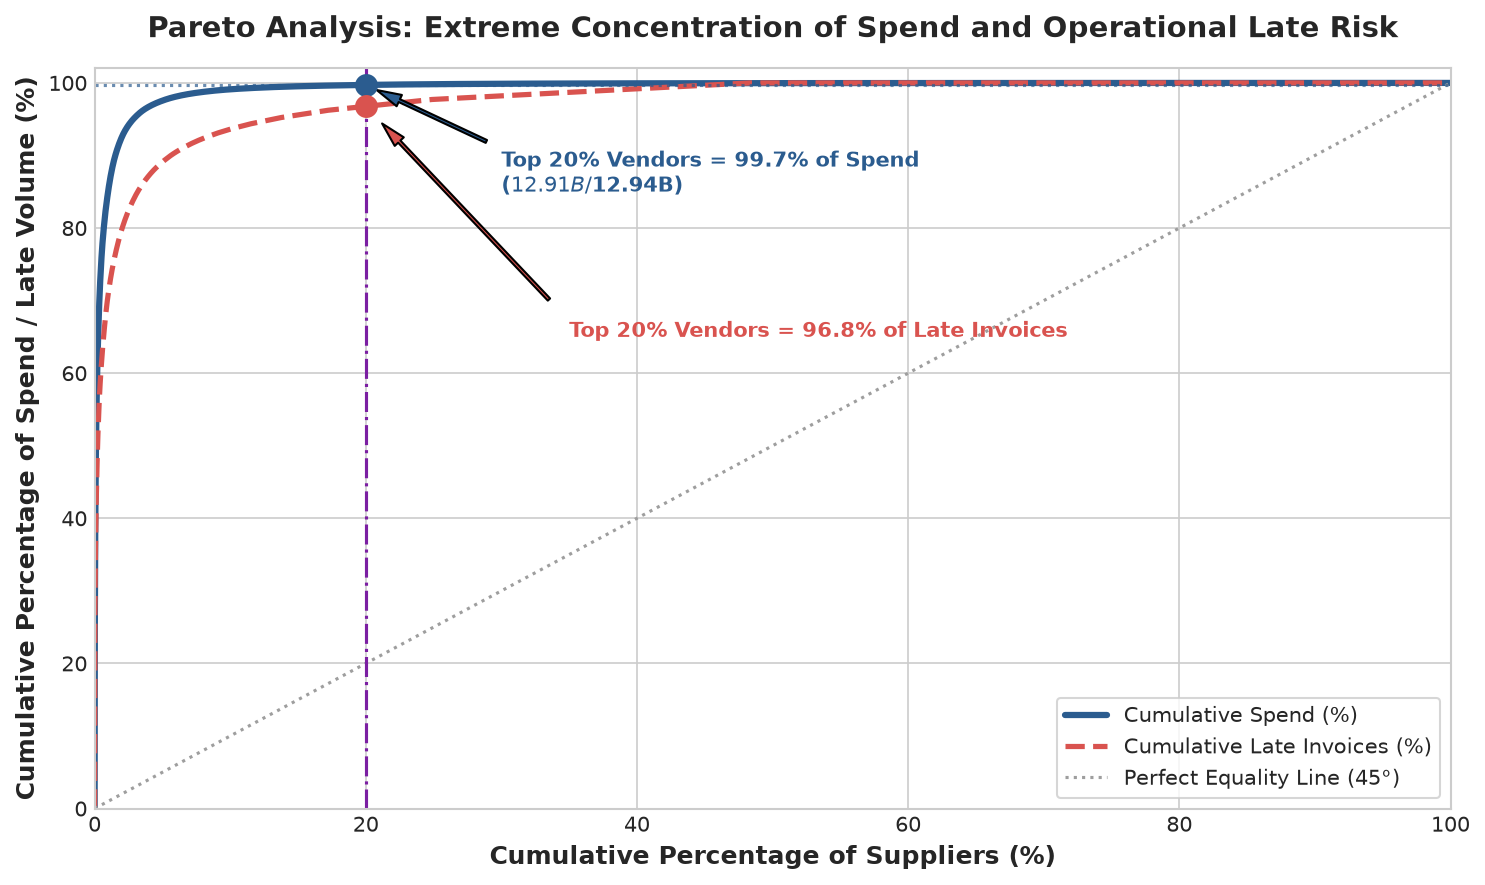

Saved: D:\Antigravity\projects\project_data_analysis\.worktrees\feat-ds-rebuild\artifacts\eda\06_vendor_pareto.png


In [7]:
vendor_stats = df.groupby("supplier_number").agg(
    total_spend=("invoice_amount", "sum"),
    invoice_count=("invoice_number", "count"),
    late_count=("is_late", "sum")
).reset_index()

total_vendors = len(vendor_stats)
total_spend = vendor_stats["total_spend"].sum()
total_late = df["is_late"].sum()

# Sort vendors by spend descending
vendor_stats_spend = vendor_stats.sort_values(by="total_spend", ascending=False).reset_index(drop=True)
top_20pct_count = int(np.ceil(0.20 * total_vendors))
top_20_spend = vendor_stats_spend.iloc[:top_20pct_count]["total_spend"].sum()
top_20_spend_pct = (top_20_spend / total_spend) * 100

top_10_vendors_spend = vendor_stats_spend.iloc[:10]["total_spend"].sum()
top_10_spend_pct = (top_10_vendors_spend / total_spend) * 100

# Sort vendors by late count descending
vendor_stats_late = vendor_stats.sort_values(by="late_count", ascending=False).reset_index(drop=True)
top_20_late = vendor_stats_late.iloc[:top_20pct_count]["late_count"].sum()
top_20_late_pct = (top_20_late / total_late) * 100

print(f"Total Unique Suppliers: {total_vendors:,d}")
print(f"Total Portfolio Spend: ${total_spend:,.2f}")
print(f"Top 10 Suppliers Spend Share: {top_10_spend_pct:.2f}%")
print(f"Top 20% Suppliers ({top_20pct_count:,d}) Spend Share: {top_20_spend_pct:.2f}%")
print(f"Top 20% Suppliers Late Invoices Share: {top_20_late_pct:.2f}%")

# Compute Lorenz Curves for Spend and Late Counts
cum_vendors = np.linspace(0, 100, len(vendor_stats))
cum_spend = np.insert(np.cumsum(vendor_stats_spend["total_spend"]) / total_spend * 100, 0, 0)[:-1]
cum_late = np.insert(np.cumsum(vendor_stats_late["late_count"]) / total_late * 100, 0, 0)[:-1]

# Plotting Pareto Lorenz Curve
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(cum_vendors, cum_spend, color="#2b5c8f", linewidth=3, label="Cumulative Spend (%)")
ax.plot(cum_vendors, cum_late, color="#d9534f", linewidth=2.5, linestyle="--", label="Cumulative Late Invoices (%)")
ax.plot([0, 100], [0, 100], color="#9e9e9e", linestyle=":", linewidth=1.5, label="Perfect Equality Line (45°)")

# Highlight 20% vendor mark
ax.axvline(20, color="#7b1fa2", linestyle="-.", linewidth=1.5)
ax.axhline(top_20_spend_pct, color="#2b5c8f", linestyle=":", alpha=0.7)
ax.scatter([20], [top_20_spend_pct], color="#2b5c8f", s=100, zorder=5)
ax.annotate(f"Top 20% Vendors = {top_20_spend_pct:.1f}% of Spend\n(${top_20_spend/1e9:.2f}B / ${total_spend/1e9:.2f}B)",
            xy=(20, top_20_spend_pct), xytext=(30, 85),
            arrowprops=dict(facecolor='#2b5c8f', shrink=0.08, width=1.5, headwidth=6),
            fontsize=10, fontweight="bold", color="#2b5c8f")

ax.scatter([20], [top_20_late_pct], color="#d9534f", s=100, zorder=5)
ax.annotate(f"Top 20% Vendors = {top_20_late_pct:.1f}% of Late Invoices",
            xy=(20, top_20_late_pct), xytext=(35, 65),
            arrowprops=dict(facecolor='#d9534f', shrink=0.08, width=1.5, headwidth=6),
            fontsize=10, fontweight="bold", color="#d9534f")

ax.set_xlabel("Cumulative Percentage of Suppliers (%)")
ax.set_ylabel("Cumulative Percentage of Spend / Late Volume (%)")
ax.set_title("Pareto Analysis: Extreme Concentration of Spend and Operational Late Risk", pad=15)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.legend(loc="lower right", frameon=True)

plt.tight_layout()
fig_pareto_path = eda_artifacts_dir / "06_vendor_pareto.png"
fig.savefig(fig_pareto_path, dpi=300)
plt.show()
print(f"Saved: {fig_pareto_path}")

---
## Section 7: Key Findings & Modeling Implications

1. **Target Imbalance & Threshold**:
   - The Net 30 threshold produces a well-behaved binary classification target (`is_late = 1` for $24.76\%$ of clean invoices, class ratio $\approx 3:1$).
   - A sharp spike occurs at exactly $30$ days ($p50 = 30$ and $p75 = 30$).

2. **Mitigating Right-Censoring**:
   - Invoices issued in November and December 2025 exhibit severe downward bias due to truncation at `max(Payment_Date) = 2025-12-31`.
   - Limiting the evaluation period to `test_end = 2025-10-31` provides an exact $61$-day buffer matching the 90th percentile of `days_to_pay`, safeguarding model validation against censorship leakage.

3. **Seasonality & Operational Signals**:
   - Fiscal year-end (May rush and June acceleration) strongly influences late risk ($p < 10^{-50}$).
   - Operating Unit is a powerful predictive feature: `METRO_MNPS` has an $11.26\%$ higher late rate than `METRO_GG` (Cramér's $V = 0.1299$, $p < 10^{-100}$).

4. **Extreme Spend & Risk Concentration**:
   - Top $20\%$ of suppliers drive $99.73\%$ of spend and $96.78\%$ of late payments. Target encoding or historical vendor risk aggregation will be critical features in Phase 2.